# T8 率定诊断与 T9 高维参数边界提案

**TL;DR**

- 正式 T8 使用 17 个活动参数、240 个 realization 和 448 个非零权重观测；末轮最低 Phi 为 realization 53 的 976.022。
- 10/17 参数出现明显边界堆积，其中 `XFINT`、`TB2` 已完全坍缩到边界；现有空间不足以支持可信后验解释。
- 旧 `stage4_full_v12` 不能直接迁移：108 个值中 26 个是初始水氮或土壤容重，且旧/新 ECO 基线语义不兼容。
- 下一轮建议使用 54 个共享作物参数进行高维诊断率定；实测土壤与逐季初始条件保持固定，旧解只作为诊断种子，不作为正式先验中心。


## Context and methods

This notebook reads the formal T8 run, independently reproduces realization-53 metrics, audits posterior boundary pile-up, compares the legacy single-season parameter set, and exports a machine-readable T9 candidate table. It does **not** alter frozen bounds or launch calibration.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
RUN = ROOT / "workspace" / "runs" / "eggplant_t8_joint_formal_20260721_234458"
PREFIX = RUN.name
BOUNDS = ROOT / "data" / "parameter_registry" / "bounds_frozen" / "eggplant" / "eggplant_t7_formal_v5_20260721.csv"
BASE_CANDIDATE = ROOT / "data" / "parameter_registry" / "bounds_proposals" / "eggplant" / "eggplant_formal_multiseason_candidate_v4_20260721.csv"
OUT = ROOT / "docs" / "reports" / "data"
OUT.mkdir(parents=True, exist_ok=True)

legacy_candidates = list(Path(r"C:\DSSAT48_bak\Tomato_Cal").glob("**/stage4_full_v12_best_parameters_fixed.csv"))
assert legacy_candidates, "Legacy best-parameter CSV not found"
LEGACY = legacy_candidates[0]

bounds = pd.read_csv(BOUNDS)
par0 = pd.read_csv(RUN / f"{PREFIX}.0.par.csv")
par4 = pd.read_csv(RUN / f"{PREFIX}.4.par.csv")
obs4 = pd.read_csv(RUN / f"{PREFIX}.4.obs.csv")
phi = pd.read_csv(RUN / f"{PREFIX}.phi.actual.csv")
registry = pd.read_csv(RUN / f"{PREFIX}_observation_registry.csv")
legacy = pd.read_csv(LEGACY)

for df in (par0, par4, obs4):
    df["real_name"] = df["real_name"].astype(str)
par0 = par0.set_index("real_name")
par4 = par4.set_index("real_name")
obs4 = obs4.set_index("real_name")
legacy_map = dict(zip(legacy["name"].str.lower(), legacy["value"]))

summary = {
    "t8_active_parameters": int((bounds["status"] == "active").sum()),
    "t8_realizations": len(par4),
    "registry_observations": len(registry),
    "active_observations": int((registry["weight"] > 0).sum()),
    "legacy_parameter_count": len(legacy),
    "legacy_environment_or_initial_count": int(legacy["name"].str.lower().str.match(r"^(ic_|soil_)").sum()),
}
summary

{'t8_active_parameters': 17,
 't8_realizations': 240,
 'registry_observations': 472,
 'active_observations': 448,
 'legacy_parameter_count': 108,
 'legacy_environment_or_initial_count': 26}

## Findings 1 — T8 posterior boundary audit

In [2]:
active = bounds.loc[bounds["status"].eq("active")].copy()
rows = []
for _, b in active.iterrows():
    n = b["name"].lower()
    lo, hi = float(b["lower"]), float(b["upper"])
    span = hi - lo
    prior = pd.to_numeric(par0[n])
    post = pd.to_numeric(par4[n])
    rows.append({
        "name": b["name"], "lower": lo, "upper": hi,
        "legacy_value": legacy_map.get(n, np.nan),
        "t8_best53": float(par4.loc["53", n]),
        "post_q025": post.quantile(0.025), "post_median": post.median(),
        "post_q975": post.quantile(0.975), "post_sd": post.std(),
        "sd_ratio_post_prior": post.std() / prior.std() if prior.std() else np.nan,
        "within_2pct_lower": (post <= lo + 0.02 * span).mean(),
        "within_2pct_upper": (post >= hi - 0.02 * span).mean(),
        "at_lower": np.isclose(post, lo, atol=1e-7).mean(),
        "at_upper": np.isclose(post, hi, atol=1e-7).mean(),
    })
audit = pd.DataFrame(rows)
audit["max_near_boundary"] = audit[["within_2pct_lower", "within_2pct_upper"]].max(axis=1)
audit["boundary_flag"] = np.select(
    [audit["max_near_boundary"] >= 0.75, audit["max_near_boundary"] >= 0.20],
    ["severe", "material"], default="none")
audit = audit.sort_values(["max_near_boundary", "name"], ascending=[False, True])
audit.to_csv(OUT / "T9_T8_posterior_boundary_audit_20260722.csv", index=False)
audit

,name,lower,upper,legacy_value,t8_best53,post_q025,post_median,post_q975,post_sd,sd_ratio_post_prior,within_2pct_lower,within_2pct_upper,at_lower,at_upper,max_near_boundary,boundary_flag
9,TB2,8.000,12.00,10.500000,12.000000,12.000000,12.000000,12.000000,0.000000e+00,0.000000e+00,0.000000,1.000000,0.000000,1.000000,1.000000,severe
6,XFINT,0.120,0.35,0.357290,0.350000,0.350000,0.350000,0.350000,5.562716e-17,1.555132e-15,0.000000,1.000000,0.000000,1.000000,1.000000,severe
3,FL-SD,7.000,21.00,7.000000,7.000000,7.000000,7.000000,7.000000,1.489314e-01,8.523140e-02,0.995833,0.000000,0.991667,0.000000,0.995833,severe
1,XFRT,0.730,0.99,0.986485,0.990000,0.990000,0.990000,0.990000,1.380895e-03,5.011854e-02,0.000000,0.995833,0.000000,0.991667,0.995833,severe
12,TO12,20.000,27.50,22.000000,20.000000,20.000000,20.000000,20.000000,4.211066e-02,4.535222e-02,0.991667,0.000000,0.987500,0.000000,0.991667,severe
2,EM-FL,23.000,31.00,26.317700,23.000000,23.000000,23.000000,23.112840,6.525957e-02,7.993327e-02,0.979167,0.000000,0.962500,0.000000,0.979167,severe
13,TO22,28.000,33.00,28.887400,33.000000,32.469900,33.000000,33.000000,1.386652e-01,1.619148e-01,0.000000,0.908333,0.000000,0.883333,0.908333,severe
15,NMOBMX,0.080,0.40,0.250000,0.080000,0.080000,0.080000,0.110046,8.567083e-03,2.573813e-01,0.887500,0.000000,0.858333,0.000000,0.887500,severe
14,NSTFAC,0.300,0.85,NaN,0.820598,0.774562,0.850000,0.850000,2.184161e-02,2.492892e-01,0.000000,0.770833,0.000000,0.745833,0.770833,severe
0,LFMAX,1.270,1.36,1.270000,1.271150,1.270069,1.271210,1.286563,4.476983e-03,5.390475e-01,0.733333,0.000000,0.020833,0.000000,0.733333,material


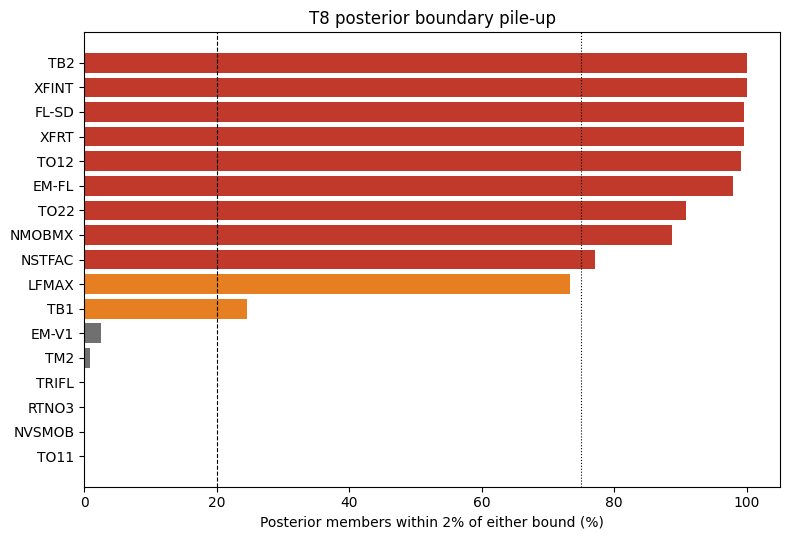

In [3]:
plot_data = audit.sort_values("max_near_boundary")
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(plot_data["name"], 100 * plot_data["max_near_boundary"],
        color=np.where(plot_data["boundary_flag"].eq("severe"), "#C0392B",
              np.where(plot_data["boundary_flag"].eq("material"), "#E67E22", "#707070")))
ax.axvline(20, color="black", lw=0.8, ls="--")
ax.axvline(75, color="black", lw=0.8, ls=":")
ax.set_xlabel("Posterior members within 2% of either bound (%)")
ax.set_ylabel("")
ax.set_title("T8 posterior boundary pile-up")
plt.tight_layout()
plt.show()

## Findings 2 — independent reproduction of realization-53 metrics

In [4]:
families = ["ADAP", "SWAD", "CNAM", "PWAD", "PWAI", "LWAD", "LAID", "LAIX", "HWAM", "HIAM"]
def family(group):
    s = str(group).upper()
    return next((x for x in families if x in s), "OTHER")

d = registry.copy()
d["simulated"] = d["obsnme"].str.lower().map(obs4.loc["53"])
d["family"] = d["obgnme"].map(family)
d = d.loc[d["weight"] > 0].copy()
d["residual"] = d["simulated"] - d["obsval"]

def metrics(x):
    y = x["obsval"].to_numpy(float)
    yh = x["simulated"].to_numpy(float)
    r = yh - y
    rmse = np.sqrt(np.mean(r**2))
    ss = np.sum((y - y.mean())**2)
    r2 = np.corrcoef(y, yh)[0, 1]**2 if len(y) > 1 and y.std() > 0 and yh.std() > 0 else np.nan
    return pd.Series({
        "n": len(x), "RMSE": rmse,
        "RRMSE_pct": 100 * rmse / y.mean() if y.mean() else np.nan,
        "NSE": 1 - np.sum(r**2) / ss if ss else np.nan, "R2": r2,
        "bias_sim_minus_obs": r.mean(),
        "Phi": np.sum((r * x["weight"].to_numpy(float))**2),
    })

by_family = d.groupby("family").apply(metrics, include_groups=False)
by_season_family = d.groupby(["season_id", "family"]).apply(metrics, include_groups=False)
mixed = metrics(d)
phi53 = float(phi.loc[phi["iteration"].eq(4), "53"].iloc[0])
assert np.isclose(mixed["Phi"], phi53, atol=1e-3)
print("Mixed-unit reproduction only (not a valid paper-level aggregate):")
display(mixed.to_frame("value"))
display(by_family)
display(by_season_family)

Mixed-unit reproduction only (not a valid paper-level aggregate):


,value
n,448.000000
RMSE,853.606206
RRMSE_pct,103.684577
NSE,0.341760
R2,0.435353
bias_sim_minus_obs,-321.483368
Phi,976.022317


,n,RMSE,RRMSE_pct,NSE,R2,bias_sim_minus_obs,Phi
family,,,,,,,
ADAP,8.0,19.000000,42.222222,NaN,NaN,-19.000000,0.573016
CNAM,8.0,83.593839,56.770010,-31.537186,0.515648,54.375000,10.684908
LAID,64.0,2.854081,167.345679,-3.750052,0.679370,0.980547,15.190258
LAIX,16.0,5.383649,173.128572,-33.973026,0.878883,2.737250,84.010667
LWAD,64.0,946.976183,131.154459,-1.961510,0.294731,97.078125,311.917875
PWAD,112.0,1465.224381,73.815494,-0.197137,0.491451,-1032.509821,471.102740
PWAI,112.0,268.874383,70.376095,-1.739911,0.114551,-169.607143,19.829704
SWAD,64.0,565.021349,64.792543,0.440210,0.661899,-249.843750,62.713149


n         RMSE   RRMSE_pct         NSE        R2  \
season_id family                                                        
25FA      LAID    24.0     1.204306   74.575820   -1.737466  0.856331   
          LAIX     8.0     1.556743   68.677302  -28.485048  0.472239   
          LWAD    24.0   883.580476   99.698784   -1.625362  0.873752   
          PWAD    24.0   255.125454   28.133665    0.525271  0.895003   
          PWAI    24.0   218.836766   48.272816   -5.091352  0.051224   
          SWAD    24.0   810.456533   98.252042   -1.911610  0.918629   
25SP      ADAP     8.0    19.000000   42.222222         NaN       NaN   
          CNAM     8.0    83.593839   56.770010  -31.537186  0.515648   
          LAID    40.0     3.487553  198.170522   -4.030127  0.892276   
          LAIX     8.0     7.452779  188.558605 -358.696685  0.452887   
          LWAD    40.0   983.053178  157.666909   -2.449231  0.877419   
          PWAD    88.0  1647.617780   72.294925   -0.474092  0.736791   
          PWAI    88.0   280.978725   77.487082   -1.660584  0.100453   
          SWAD    40.0   341.606096   37.941478    0.849424  0.882306   

                  bias_sim_minus_obs         Phi  
season_id family                                  
25FA      LAID             -1.068167    1.014233  
          LAIX             -1.529250    3.512243  
          LWAD           -735.375000  101.832321  
          PWAD            206.891667    3.060611  
          PWAI             19.458333    2.814823  
          SWAD           -692.291667   48.385988  
25SP      ADAP            -19.000000    0.573016  
          CNAM             54.375000   10.684908  
          LAID              2.209775   14.176025  
          LAIX              7.003750   80.498424  
          LWAD            596.550000  210.085554  
          PWAD          -1370.528409  468.042129  
          PWAI           -221.170455   17.014880  
          SWAD             15.625000   14.327161

**Interpretation caveat.** The reproduced mixed-unit RMSE/RRMSE/NSE combines days, LAI and kg ha⁻¹. It is useful only as a code-reproduction check. Scientific reporting must remain by variable family and season. Also, `bias = simulated − observed`; therefore ADAP bias −19 d means flowering is simulated about 19 d **too early**.

## Findings 3 — legacy single-season result is useful but confounded

In [5]:
legacy_names = legacy["name"].str.lower()
legacy_categories = pd.Series({
    "initial_water": legacy_names.str.match(r"^ic_sh2o").sum(),
    "initial_nitrate": legacy_names.str.match(r"^ic_sno3").sum(),
    "initial_ammonium": legacy_names.str.match(r"^ic_snh4").sum(),
    "soil_bulk_density": legacy_names.str.match(r"^soil_sbdm").sum(),
    "other_crop_or_process": (~legacy_names.str.match(r"^(ic_|soil_)")).sum(),
})
legacy_categories.to_frame("count")

,count
initial_water,5
initial_nitrate,5
initial_ammonium,5
soil_bulk_density,11
other_crop_or_process,82


In [6]:
old_metrics_paths = list(Path(r"C:\DSSAT48_bak\Tomato_Cal").glob("**/metrics_grid_v12_vs_v13_n_response.csv"))
if old_metrics_paths:
    old_metrics = pd.read_csv(old_metrics_paths[0])
    old_summary = old_metrics[(old_metrics["prefix"] == "stage4_full_v12") & (old_metrics["scope"] == "overall")]
    display(old_summary[["source", "variable", "n", "rmse", "nrmse_pct", "d_index"]])
else:
    old_summary = pd.DataFrame()

,source,variable,n,rmse,nrmse_pct,d_index
0,harvest_curve,dry_cum,110,528.805760,20.803191,0.957578
1,harvest_curve,dry_inc,110,174.201500,42.582589,0.752737
2,harvest_total,dry_total,10,937.019975,20.822203,0.319208
3,process,LAID,50,0.650577,36.193433,0.956246
4,process,LWAD,50,202.914021,32.357522,0.964238
5,process,SWAD,50,348.911708,38.284729,0.952116
6,joint,HWAM,10,4495.205513,99.891236,0.085280
7,joint,LAIX,10,1.403866,34.240636,0.493529
8,joint,CNAM,0,NaN,NaN,NaN
9,joint,CNAA,0,NaN,NaN,NaN


The legacy fit is strong for the XXQL2501 harvest curve and process trajectories, but it is not uniformly excellent: the archived `HWAM` diagnostic has about 99.9% NRMSE, and no plant-N observations were available. Twenty-six of 108 saved values are soil bulk density or season-specific initial water/N. The legacy result is therefore a mixed crop–environment compensation solution, not a transferable cultivar posterior.

The old and current ECO templates are also structurally incompatible (`EM-V1` old baseline about 22 versus current 39.3). The legacy best `EM-V1=15.20` must not be injected into the current multi-season template.


## Phi scale reconciliation ? old tens of thousands and current thousands are not comparable

In [7]:
old_run = old_metrics_paths[0].parents[2] / '_runs' / '20260719_074417' / 'stage4_full_v12' if old_metrics_paths else None
old_phi_total = 21552.8
old_hiam_phi = 19292.15
old_hwam_phi = 145.49388
phi_reconciliation = pd.DataFrame([
    {'case':'legacy reported minimum','phi':old_phi_total,'definition':'246 active observations; legacy transformed scales and weights'},
    {'case':'legacy minus invalid HIAM','phi':old_phi_total-old_hiam_phi,'definition':'removes HIAM bookkeeping mismatch'},
    {'case':'legacy minus invalid HIAM and duplicate HWAM','phi':old_phi_total-old_hiam_phi-old_hwam_phi,'definition':'approximately comparable valid-target order of magnitude'},
    {'case':'T8 realization 53','phi':phi53,'definition':'448 active observations; raw sigma plus family budgets'},
])
phi_reconciliation['share_of_legacy_pct'] = 100 * phi_reconciliation['phi'] / old_phi_total
phi_reconciliation.to_csv(OUT / 'T9_phi_scale_reconciliation_20260722.csv', index=False)
phi_reconciliation

,case,phi,definition,share_of_legacy_pct
0,legacy reported minimum,21552.80000,246 active observations; legacy transformed sc...,100.000000
1,legacy minus invalid HIAM,2260.65000,removes HIAM bookkeeping mismatch,10.488892
2,legacy minus invalid HIAM and duplicate HWAM,2115.15612,approximately comparable valid-target order of...,9.813834
3,T8 realization 53,976.02200,448 active observations; raw sigma plus family...,4.528516


## T9 high-dimensional crop-parameter proposal

In [8]:
candidate = pd.read_csv(BASE_CANDIDATE)
candidate = candidate.loc[~candidate["name"].str.startswith(("SOIL_", "IC_"))].copy()

overrides = {
    "LFMAX": (0.90, 1.50), "SIZLF": (240.0, 380.0), "SLAVR": (220.0, 340.0),
    "XFRT": (0.70, 1.00), "EM-FL": (23.0, 42.0), "FL-SD": (5.0, 25.0),
    "FL-SH": (1.0, 6.0), "PODUR": (25.0, 60.0), "SDPDV": (80.0, 300.0),
    "SFDUR": (8.0, 30.0), "RHGHT": (0.80, 2.20), "RWDTH": (0.70, 2.00),
    "TRIFL": (0.20, 1.00), "EM-V1": (10.0, 40.0), "JU-R0": (2.0, 12.0),
    "LNGSH": (25.0, 50.0), "PL-EM": (3.0, 12.0), "PM06": (0.35, 0.75),
    "PM09": (0.60, 1.00), "XFINT": (0.08, 0.50), "XFPHT": (35.0, 70.0),
    "XMAGE": (8.0, 30.0), "KCAN": (0.50, 0.90), "KC_SLOPE": (0.04, 0.20),
    "PARMAX": (25.0, 55.0), "PHTMAX": (40.0, 80.0), "ATOP": (0.55, 1.00),
    "FRLFF": (0.25, 0.50), "FRSTMF": (0.35, 0.70), "PORPT": (0.12, 0.30),
    "RTNO3": (0.008, 0.050), "RTNH4": (0.008, 0.050), "RTEXF": (0.05, 0.25),
    "WTFSD": (0.35, 0.75), "FINREF": (150.0, 320.0), "SIZREF": (200.0, 420.0),
    "SLAREF": (200.0, 420.0), "VSSINK": (1.5, 8.0),
    "TB1": (6.0, 14.0), "TB2": (6.0, 14.0), "TB3": (6.0, 14.0),
    "TO11": (18.0, 27.0), "TO12": (18.0, 27.0), "TO13": (18.0, 27.0),
    "TO21": (27.5, 36.0), "TO22": (27.5, 36.0), "TO23": (27.5, 36.0),
    "TM1": (36.5, 48.0), "TM2": (36.5, 48.0), "TM3": (36.5, 48.0),
    "NSTFAC": (0.20, 1.00), "NMOBMX": (0.02, 0.50),
    "NVSMOB": (0.15, 0.60), "NRCVR": (0.03, 0.35),
}
for name, (lo, hi) in overrides.items():
    m = candidate["name"].eq(name)
    assert m.sum() == 1, f"Missing proposed parameter {name}"
    candidate.loc[m, ["lower", "upper"]] = [lo, hi]

# Keep the control-file base realization inside the ordered temperature
# envelopes; these are neutral working starts, not posterior centers.
candidate.loc[candidate["name"].eq("TM2"), "init"] = 40.0
candidate.loc[candidate["name"].eq("EM-V1"), "init"] = 22.0
candidate.loc[candidate["name"].eq("TO12"), "init"] = 25.0

candidate.loc[candidate["name"].eq("FL-VS"), ["init", "lower", "upper", "status"]] = [120.0, 100.0, 140.0, "active"]
candidate.loc[candidate["name"].eq("FRCNOD"), "status"] = "fixed"
candidate["legacy_value"] = candidate["name"].str.lower().map(legacy_map)
candidate["t8_best53_value"] = candidate["name"].str.lower().map(par4.loc["53"].to_dict())
candidate["proposal_role"] = np.where(
    candidate["status"].eq("active"), "shared_crop_highdim",
    np.where(candidate["name"].eq("FRCNOD"), "fixed_nonlegume",
    np.where(candidate["name"].eq("FL-VS"), "fixed_unidentified_structure", "fixed_structural_or_irrelevant")))
candidate["legacy_transfer_policy"] = np.where(
    candidate["name"].isin(["XFPHT"]), "do_not_transfer_template_incompatible",
    np.where(candidate["legacy_value"].notna() & candidate["status"].eq("active"), "diagnostic_seed_only", "not_used"))
candidate["proposal_note"] = np.select(
    [candidate["name"].isin(["LFMAX", "XFRT", "EM-FL", "FL-SD", "XFINT", "TB2", "TO12", "TO22", "NSTFAC", "NMOBMX"]),
     candidate["status"].eq("active")],
    ["T8 boundary pile-up; widen within process-safe envelope and add compensating process parameters",
     "T9 high-dimensional shared crop/process parameter"],
    default="Retain fixed status; not identified by current observations")

cols = ["name", "init", "lower", "upper", "status", "pargp", "file", "proposal_role",
        "legacy_value", "t8_best53_value", "legacy_transfer_policy", "proposal_note"]
candidate_out = candidate[cols].copy()
candidate_out.to_csv(OUT / "T9_highdim_parameter_proposal_20260722.csv", index=False)
print(candidate_out["status"].value_counts())
display(candidate_out[candidate_out["status"].eq("active")])

status
active    55
fixed      9
Name: count, dtype: int64


,name,init,lower,upper,status,pargp,file,proposal_role,legacy_value,t8_best53_value,legacy_transfer_policy,proposal_note
0,LFMAX,1.270,0.900,1.50,active,CUL_Growth,TMGRO048.CUL.base,shared_crop_highdim,1.270000,1.271150,diagnostic_seed_only,T8 boundary pile-up; widen within process-safe...
1,SIZLF,297.100,240.000,380.00,active,CUL_Growth,TMGRO048.CUL.base,shared_crop_highdim,320.622000,NaN,diagnostic_seed_only,T9 high-dimensional shared crop/process parameter
2,SLAVR,293.000,220.000,340.00,active,CUL_Growth,TMGRO048.CUL.base,shared_crop_highdim,282.970000,NaN,diagnostic_seed_only,T9 high-dimensional shared crop/process parameter
7,XFRT,0.990,0.700,1.00,active,CUL_HarvestPartition,TMGRO048.CUL.base,shared_crop_highdim,0.986485,0.990000,diagnostic_seed_only,T8 boundary pile-up; widen within process-safe...
8,EM-FL,23.300,23.000,42.00,active,CUL_PhenologyHarvest,TMGRO048.CUL.base,shared_crop_highdim,26.317700,23.000000,diagnostic_seed_only,T8 boundary pile-up; widen within process-safe...
10,FL-SD,8.100,5.000,25.00,active,CUL_PhenologyHarvest,TMGRO048.CUL.base,shared_crop_highdim,7.000000,7.000000,diagnostic_seed_only,T8 boundary pile-up; widen within process-safe...
11,FL-SH,2.000,1.000,6.00,active,CUL_PhenologyHarvest,TMGRO048.CUL.base,shared_crop_highdim,3.280540,2.000000,diagnostic_seed_only,T9 high-dimensional shared crop/process parameter
12,PODUR,33.000,25.000,60.00,active,CUL_PhenologyHarvest,TMGRO048.CUL.base,shared_crop_highdim,30.000000,33.000000,diagnostic_seed_only,T9 high-dimensional shared crop/process parameter
14,SDPDV,111.400,80.000,300.00,active,CUL_PhenologyHarvest,TMGRO048.CUL.base,shared_crop_highdim,100.000000,111.400000,diagnostic_seed_only,T9 high-dimensional shared crop/process parameter
15,SFDUR,11.700,8.000,30.00,active,CUL_PhenologyHarvest,TMGRO048.CUL.base,shared_crop_highdim,27.000000,11.700000,diagnostic_seed_only,T9 high-dimensional shared crop/process parameter


## Takeaways and next-run controls

1. Run a **diagnostic high-dimensional IES** first (55 active crop/process parameters, 600 realizations, 2 updates). Use T8-best and compatible legacy values only as named diagnostic starts; do not call this ensemble a posterior.
2. After preflight and bound review, run the **formal inference ensemble** from an independent, explicitly documented prior (prefer 800 realizations, 4 updates). Reusing a posterior or single-season optimum as the prior on the same observations double-counts the data.
3. Keep measured weather, irrigation, fertilizer, soil profile and per-season initial water/N fixed. Add soil hydraulic nuisance parameters only when soil-water observations and measurement uncertainty can identify them.
4. Preserve `SYMBI=N`; keep `FRCNOD` fixed. Allow `FL-VS` in the user-approved 100?140 range, but interpret it with a strong prior because terminal growth is not directly observed.
5. Do not simultaneously treat full incremental and cumulative harvest series as independent observations. Use incremental harvest as the primary event series, optionally retain final cumulative yield as an anchor, and keep the full cumulative curve diagnostic.
6. Keep ADAP as a low-priority constraint for transplanted indeterminate eggplant. Use a reduced PHENO family budget and do not make missing anthesis a primary rejection criterion; process and harvest outputs must still remain finite.
7. Keep XXQL2601 sealed for independent validation.
